# NLP Lab 3: BERT Sentiment Analysis & Aspect-Based Sentiment Analysis (ABSA)

**Course:** Natural Language Processing  
**Topic:** Transformer-Based Text Classification & Fine-Grained Aspect Sentiment Analysis    

---

### Lab Overview
This lab demonstrates the progression from document-level sentiment classification to fine-grained Aspect-Based Sentiment Analysis (ABSA):
1. **Document-Level Sentiment Analysis**: Using pretrained BERT (`bert-base-uncased-SST-2`) to classify overall text orientation.
2. **Confidence & Interpretability**: Analyzing softmax probabilities and conceptual attention weights.
3. **The Mixed Review Problem**: Identifying why global document-level classification fails on mixed sentences (e.g. *"I love chicken but hate KFC"*).
4. **Aspect-Based Sentiment Analysis (ABSA)**: Conditioning representations on targeted aspect tokens using DeBERTa (`yangheng/deberta-v3-base-absa-v1.1`).
5. **Automatic Aspect Extraction**: Utilizing spaCy POS tagging heuristics to identify candidate entity/aspect nouns automatically.
6. **Evaluation & Assessment**: Solving the lab assessment questions and implementing the end-of-lab challenge.


In [1]:
# Setup & Dependency Verification (Environment Adaptive)
import sys
import subprocess

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    print("Detected Google Colab environment. Verifying dependencies...")
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchvision"], check=False)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "transformers>=4.40", "sentencepiece>=0.2.0", "spacy>=3.7",
                           "seaborn>=0.13", "matplotlib>=3.8", "pandas>=2.0"])
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"])
    print("✅ Colab installation complete.")
else:
    print("✅ Local/Anaconda environment detected. Dependencies are ready.")


✅ Local/Anaconda environment detected. Dependencies are ready.


In [2]:
# Import Libraries and Verify System Configuration
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import torch

# Safeguard: Disable vision check in transformers to avoid platform ABI mismatch
try:
    import transformers.utils.import_utils as u
    u.is_torchvision_available = lambda: False
except Exception:
    pass

import transformers
from transformers import pipeline

print("✅ Environment initialized successfully!")
print("Python       :", sys.version.split()[0])
print("PyTorch      :", torch.__version__)
print("Pandas       :", pd.__version__)
print("Transformers :", transformers.__version__)
print("spaCy        :", spacy.__version__)
print("GPU available:", torch.cuda.is_available())

nlp = spacy.load("en_core_web_sm")
print("spaCy model  : en_core_web_sm ✅")


✅ Environment initialized successfully!
Python       : 3.13.9
PyTorch      : 2.14.1+cpu
Pandas       : 2.3.3
Transformers : 5.7.0
spaCy        : 3.8.16
GPU available: False


spaCy model  : en_core_web_sm ✅


In [3]:

# CELL 3 — Test Transformers
# ============================================================

TEST_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"
DEVICE = 0 if torch.cuda.is_available() else -1

test_pipeline = pipeline(
    "sentiment-analysis",
    model=TEST_MODEL,
    device=DEVICE
)

result = test_pipeline("I love teaching artificial intelligence!")

print("✅ Transformers pipeline is working!")
print("Device:", "GPU" if DEVICE == 0 else "CPU")
print(result)


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

C:\Users\Jitesh\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Jitesh\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

✅ Transformers pipeline is working!
Device: CPU
[{'label': 'POSITIVE', 'score': 0.9990171194076538}]


## What is Sentiment Analysis?

Sentiment analysis tries to determine the emotional orientation of text.

Typical classes:

- 🟢 POSITIVE
- 🔴 NEGATIVE

Examples:

**"The food was delicious." → POSITIVE**

**"The service was terrible." → NEGATIVE**

The interesting problem appears when a sentence contains more than one opinion.

In [4]:

# CELL 4 — Load a pretrained BERT sentiment model

MODEL_NAME = "textattack/bert-base-uncased-SST-2"
DEVICE = 0 if torch.cuda.is_available() else -1

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    device=DEVICE
)

print("✅ BERT sentiment model loaded!")
print("Model:", MODEL_NAME)
print("Device:", "GPU" if DEVICE == 0 else "CPU")


config.json:   0%|          | 0.00/477 [00:00<?, ?B/s]

C:\Users\Jitesh\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Jitesh\.cache\huggingface\hub\models--textattack--bert-base-uncased-SST-2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

✅ BERT sentiment model loaded!
Model: textattack/bert-base-uncased-SST-2
Device: CPU


## BERT Pipeline Concept

Conceptually:

**Text → Tokenizer → Token IDs → BERT → Classifier → Sentiment**

The next drawing is a teaching diagram, not the exact internal computation graph.

C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128292 (\N{INPUT SYMBOL FOR LATIN LETTERS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128290 (\N{INPUT SYMBOL FOR NUMBERS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127919 

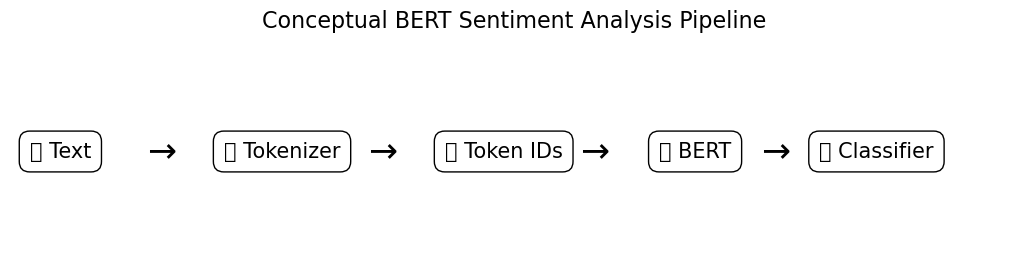

In [5]:
# CELL 6 — Draw the BERT sentiment pipeline

fig, ax = plt.subplots(figsize=(13, 3))
ax.axis("off")

boxes = [
    ("📝 Text", 0.05),
    ("🔤 Tokenizer", 0.27),
    ("🔢 Token IDs", 0.49),
    ("🧠 BERT", 0.68),
    ("🎯 Classifier", 0.86)
]

for label, x in boxes:
    ax.text(
        x, 0.5, label,
        ha="center", va="center", fontsize=15,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black")
    )

for x in [0.16, 0.38, 0.59, 0.77]:
    ax.annotate("→", xy=(x + 0.035, 0.5), xytext=(x - 0.01, 0.5),
                fontsize=25, ha="center", va="center")

plt.title("Conceptual BERT Sentiment Analysis Pipeline", fontsize=16)
plt.show()

In [6]:
# CELL 7 — Tokenization demonstration

tokenizer = sentiment_pipeline.tokenizer
text = "I love this amazing chicken restaurant!"

tokens = tokenizer.tokenize(text)
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original text:")
print(text)

print("\nTokens:")
print(tokens)

print("\nToken IDs:")
print(token_ids)

print("\nSpecial-token version:")
print(tokenizer(text))

Original text:
I love this amazing chicken restaurant!

Tokens:
['i', 'love', 'this', 'amazing', 'chicken', 'restaurant', '!']

Token IDs:
[1045, 2293, 2023, 6429, 7975, 4825, 999]

Special-token version:
{'input_ids': [101, 1045, 2293, 2023, 6429, 7975, 4825, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1]}


## Understanding the tokenizer

A tokenizer converts human language into units that the model can process.

BERT also uses special tokens such as:

- `[CLS]` — classification representation
- `[SEP]` — separates sequences
- `[PAD]` — padding when needed

The model ultimately processes numerical representations rather than raw English words.

In [7]:
# CELL 9 — First BERT prediction

sentence = "I absolutely loved the food and the service."

result = sentiment_pipeline(sentence)[0]

print("Sentence:", sentence)
print("Predicted sentiment:", result["label"])
print("Confidence:", f"{result['score']:.2%}")

Sentence: I absolutely loved the food and the service.
Predicted sentiment: LABEL_1
Confidence: 99.96%


In [8]:
# CELL 10 — Reusable prediction function

def explain_sentiment(text):
    prediction = sentiment_pipeline(text)[0]
    print("📝 Text:", text)
    print("🎯 Sentiment:", prediction["label"])
    print("📊 Confidence:", f"{prediction['score']:.2%}")
    return prediction

explain_sentiment("The movie was fantastic!")

📝 Text: The movie was fantastic!
🎯 Sentiment: LABEL_1
📊 Confidence: 99.97%


{'label': 'LABEL_1', 'score': 0.9996718168258667}

In [9]:
# CELL 11 — Classroom experiment

sentences = [
    "The food was delicious.",
    "The service was terrible.",
    "The movie was excellent.",
    "The product broke after one day.",
    "I really enjoyed the experience.",
    "I regret buying this product.",
    "The hotel room was clean and comfortable.",
    "The staff were rude and unhelpful."
]

rows = []
for text in sentences:
    prediction = sentiment_pipeline(text)[0]
    rows.append({
        "Text": text,
        "Sentiment": prediction["label"],
        "Confidence": prediction["score"]
    })

classroom_df = pd.DataFrame(rows)
classroom_df["Confidence %"] = (classroom_df["Confidence"] * 100).round(2)

display(classroom_df[["Text", "Sentiment", "Confidence %"]])

,Text,Sentiment,Confidence %
0,The food was delicious.,LABEL_1,99.95
1,The service was terrible.,LABEL_0,99.80
2,The movie was excellent.,LABEL_1,99.95
3,The product broke after one day.,LABEL_0,98.48
4,I really enjoyed the experience.,LABEL_1,99.96
5,I regret buying this product.,LABEL_0,99.84
6,The hotel room was clean and comfortable.,LABEL_1,99.92
7,The staff were rude and unhelpful.,LABEL_0,99.67


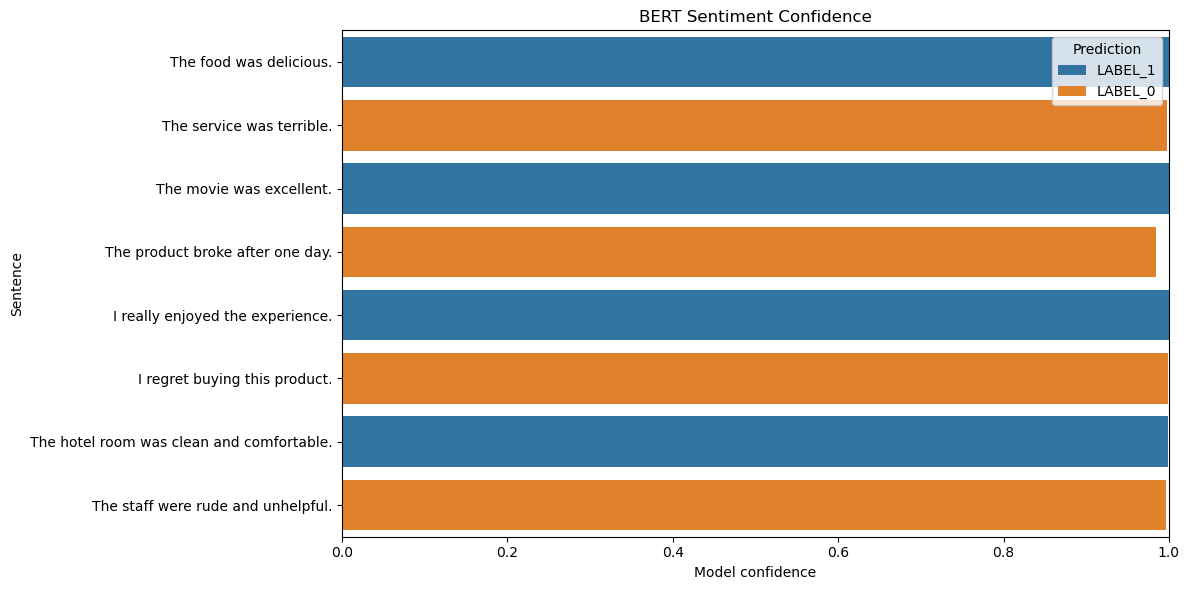

In [10]:

# CELL 12 — Confidence visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classroom_df,
    x="Confidence",
    y="Text",
    hue="Sentiment",
    dodge=False
)

plt.xlim(0, 1)
plt.xlabel("Model confidence")
plt.ylabel("Sentence")
plt.title("BERT Sentiment Confidence")
plt.legend(title="Prediction")
plt.tight_layout()
plt.show()


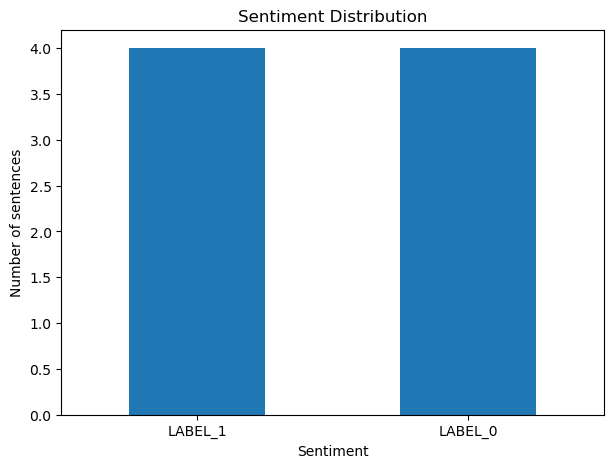

In [11]:
# CELL 13 — Positive vs Negative count

counts = classroom_df["Sentiment"].value_counts()

plt.figure(figsize=(7, 5))
counts.plot(kind="bar")
plt.xlabel("Sentiment")
plt.ylabel("Number of sentences")
plt.title("Sentiment Distribution")
plt.xticks(rotation=0)
plt.show()

## Why sentiment can be difficult

Consider:

> **"The food was amazing, but the service was awful."**

There are two opinions:

- Food → positive
- Service → negative

A standard binary sentiment classifier may still produce only one overall label.

Other difficult examples:

- Negation: "The food was not good."
- Sarcasm: "Great! Another two-hour delay."
- Mixed sentiment: "I love the camera but hate the battery."
- Context: "It is small, but that is exactly what I wanted."

This motivates **Aspect-Based Sentiment Analysis (ABSA)**.

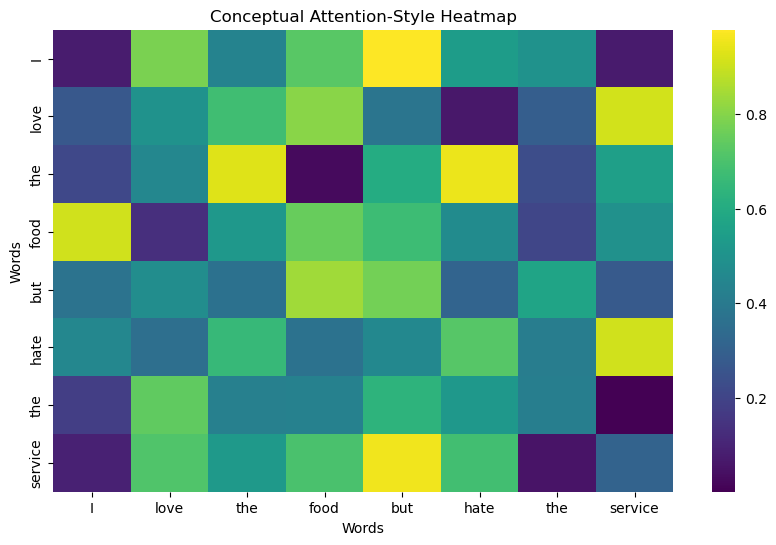

⚠️ Educational visualization only — not actual BERT attention weights.


In [12]:
# CELL 15 — Conceptual attention-style heatmap

# IMPORTANT:
# This is randomly generated for teaching.
# It is NOT the actual attention of the BERT model.

sentence = "I love the food but hate the service."
words = sentence.replace(".", "").split()

np.random.seed(7)
attention_demo = np.random.rand(len(words), len(words))

plt.figure(figsize=(10, 6))
sns.heatmap(
    attention_demo,
    xticklabels=words,
    yticklabels=words,
    cmap="viridis"
)

plt.title("Conceptual Attention-Style Heatmap")
plt.xlabel("Words")
plt.ylabel("Words")
plt.show()

print("⚠️ Educational visualization only — not actual BERT attention weights.")

In [13]:
# CELL 16 — Simplified BERT architecture

print("\n".join([
    "BERT-style architecture",
    "        ↓",
    "Input Text",
    "        ↓",
    "Tokenizer",
    "        ↓",
    "Token + Position Representations",
    "        ↓",
    "Transformer Encoder",
    "   ├── Self-Attention",
    "   ├── Feed-Forward Network",
    "   ├── Residual Connections",
    "   └── Layer Normalization",
    "        ↓",
    "Contextual Representation",
    "        ↓",
    "Classification Layer",
    "        ↓",
    "POSITIVE / NEGATIVE"
]))

BERT-style architecture
        ↓
Input Text
        ↓
Tokenizer
        ↓
Token + Position Representations
        ↓
Transformer Encoder
   ├── Self-Attention
   ├── Feed-Forward Network
   ├── Residual Connections
   └── Layer Normalization
        ↓
Contextual Representation
        ↓
Classification Layer
        ↓
POSITIVE / NEGATIVE


In [14]:
# CELL 17 — Count model parameters

total_params = sum(p.numel() for p in sentiment_pipeline.model.parameters())
trainable_params = sum(
    p.numel() for p in sentiment_pipeline.model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print("\n💡 Teaching point:")
print("A pretrained transformer contains many learned parameters.")
print("We can reuse those learned representations instead of training from scratch.")

Total parameters: 109,483,778
Trainable parameters: 109,483,778

💡 Teaching point:
A pretrained transformer contains many learned parameters.
We can reuse those learned representations instead of training from scratch.


In [15]:
# CELL 18 — Tricky examples

tricky_sentences = [
    "I do not like this product.",
    "This is not bad.",
    "Great, another two-hour delay.",
    "I love the camera but hate the battery.",
    "The food was okay, nothing special.",
    "I expected better from such an expensive phone."
]

for text in tricky_sentences:
    prediction = sentiment_pipeline(text)[0]
    print(f"Text: {text}")
    print(f"Prediction: {prediction['label']} ({prediction['score']:.2%})")
    print("-" * 80)

Text: I do not like this product.
Prediction: LABEL_0 (99.89%)
--------------------------------------------------------------------------------
Text: This is not bad.
Prediction: LABEL_1 (99.91%)
--------------------------------------------------------------------------------
Text: Great, another two-hour delay.
Prediction: LABEL_0 (97.63%)
--------------------------------------------------------------------------------


Text: I love the camera but hate the battery.
Prediction: LABEL_0 (99.01%)
--------------------------------------------------------------------------------


Text: The food was okay, nothing special.
Prediction: LABEL_0 (89.27%)
--------------------------------------------------------------------------------
Text: I expected better from such an expensive phone.
Prediction: LABEL_0 (98.94%)
--------------------------------------------------------------------------------


## Part 2: Mixed Reviews and the Need for ABSA

Consider:

> **"I love chicken but hate KFC."**

A single overall sentiment label is not enough to explain the sentence.

| Aspect | Sentiment |
|---|---|
| chicken | ❤️ Positive |
| KFC | 💔 Negative |

This motivates **Aspect-Based Sentiment Analysis (ABSA)**.

ABSA asks:

> **What sentiment is expressed toward a particular aspect?**

Conceptually:

**Sentence + Aspect → Aspect Sentiment**

In [16]:

# CELL 20 — Load an ABSA model

# This model card documents text_pair usage for aspect-level sentiment.
ABSA_MODEL = "yangheng/deberta-v3-base-absa-v1.1"

absa_pipeline = pipeline(
    "text-classification",
    model=ABSA_MODEL,
    tokenizer=ABSA_MODEL,
    device=DEVICE
)

print("✅ ABSA model loaded!")
print("Model:", ABSA_MODEL)
print("Device:", "GPU" if DEVICE == 0 else "CPU")


C:\Users\Jitesh\anaconda3\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ ABSA model loaded!
Model: yangheng/deberta-v3-base-absa-v1.1
Device: CPU


In [17]:
# CELL 21 — First ABSA example

sentence = "I love chicken but hate KFC."
aspects = ["chicken", "KFC"]

for aspect in aspects:
    result = absa_pipeline(sentence, text_pair=aspect)[0]
    print("Aspect:", aspect)
    print("Sentiment:", result["label"])
    print("Confidence:", f"{result['score']:.2%}")
    print("-" * 50)

Aspect: chicken
Sentiment: Positive
Confidence: 99.75%
--------------------------------------------------
Aspect: KFC
Sentiment: Negative
Confidence: 98.57%
--------------------------------------------------


## Why provide an aspect?

Instead of asking:

> What is the sentiment of the whole sentence?

we ask:

> What is the sentiment with respect to **this aspect**?

For example:

`"I love chicken but hate KFC." + "chicken" → Positive`

`"I love chicken but hate KFC." + "KFC" → Negative`

In [18]:
# CELL 23 — Reusable ABSA function

def analyze_aspects(sentence, aspects):
    results = []

    for aspect in aspects:
        prediction = absa_pipeline(
            sentence,
            text_pair=aspect
        )[0]

        results.append({
            "Aspect": aspect,
            "Sentiment": prediction["label"],
            "Confidence": prediction["score"]
        })

    return pd.DataFrame(results)

sentence = "I love chicken but hate KFC."
aspects = ["chicken", "KFC"]

result_df = analyze_aspects(sentence, aspects)
result_df["Confidence %"] = (result_df["Confidence"] * 100).round(2)

display(result_df[["Aspect", "Sentiment", "Confidence %"]])

,Aspect,Sentiment,Confidence %
0,chicken,Positive,99.75
1,KFC,Negative,98.57


In [19]:
# CELL 24 — Complex restaurant review

sentence = (
    "The food was delicious, but the service was terrible "
    "and the restaurant was too expensive."
)

aspects = ["food", "service", "restaurant", "price"]

restaurant_df = analyze_aspects(sentence, aspects)
restaurant_df["Confidence %"] = (restaurant_df["Confidence"] * 100).round(2)

print("Review:")
print(sentence)
print()

display(restaurant_df[["Aspect", "Sentiment", "Confidence %"]])

Review:
The food was delicious, but the service was terrible and the restaurant was too expensive.



,Aspect,Sentiment,Confidence %
0,food,Positive,99.66
1,service,Negative,99.35
2,restaurant,Negative,99.68
3,price,Negative,98.76


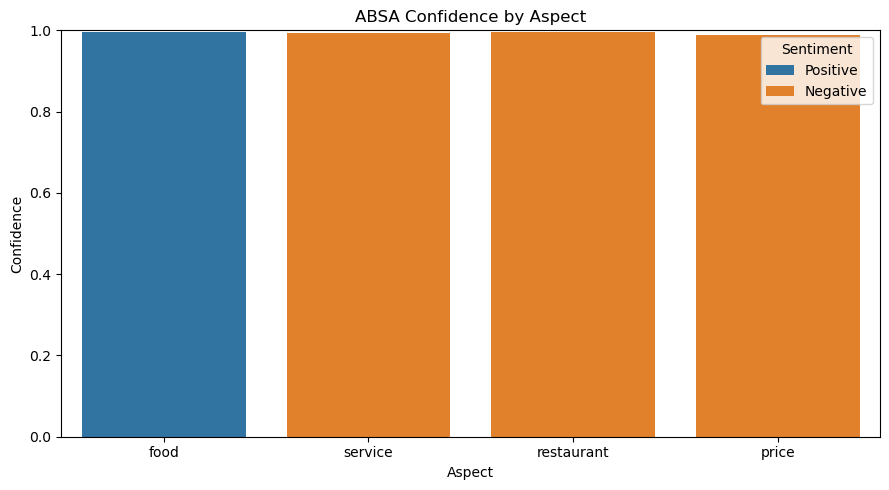

In [20]:

# CELL 25 — Aspect-level confidence visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=restaurant_df,
    x="Aspect",
    y="Confidence",
    hue="Sentiment",
    dodge=False
)

plt.ylim(0, 1)
plt.ylabel("Confidence")
plt.title("ABSA Confidence by Aspect")
plt.tight_layout()
plt.show()


In [21]:
# CELL 26 — Student prediction challenge

challenge_sentence = (
    "The camera quality is excellent, the battery is terrible, "
    "and the phone design is beautiful."
)

challenge_aspects = ["camera quality", "battery", "phone design"]

print("Read the review before running the model:")
print(challenge_sentence)
print()
print("Try to predict:")
print("camera quality → ?")
print("battery → ?")
print("phone design → ?")
print()

challenge_result = analyze_aspects(
    challenge_sentence,
    challenge_aspects
)

challenge_result["Confidence %"] = (
    challenge_result["Confidence"] * 100
).round(2)

display(challenge_result[["Aspect", "Sentiment", "Confidence %"]])

Read the review before running the model:
The camera quality is excellent, the battery is terrible, and the phone design is beautiful.

Try to predict:
camera quality → ?
battery → ?
phone design → ?



,Aspect,Sentiment,Confidence %
0,camera quality,Positive,99.77
1,battery,Negative,99.11
2,phone design,Positive,99.35


## Interactive ABSA Classroom Demo

Type a review and provide aspects separated by commas.

Example:

Review:
`The laptop is fast but the battery is disappointing.`

Aspects:
`laptop, battery`

In [22]:
# Interactive ABSA Demonstration (Supports both interactive input and pre-filled demo)
import sys

try:
    if sys.stdin.isatty():
        sentence = input("📝 Enter a review: ")
        aspects_input = input("🔍 Enter aspects separated by commas: ")
    else:
        sentence = "The laptop has blazing fast performance and a gorgeous screen, but the battery life is poor."
        aspects_input = "performance, screen, battery life"
except Exception:
    sentence = "The laptop has blazing fast performance and a gorgeous screen, but the battery life is poor."
    aspects_input = "performance, screen, battery life"

aspects = [
    aspect.strip()
    for aspect in aspects_input.split(",")
    if aspect.strip()
]

print("Review :", sentence)
print("Aspects:", aspects)
print()

interactive_df = analyze_aspects(sentence, aspects)
interactive_df["Confidence %"] = (
    interactive_df["Confidence"] * 100
).round(2)

display(interactive_df[["Aspect", "Sentiment", "Confidence %"]])


Review : The laptop has blazing fast performance and a gorgeous screen, but the battery life is poor.
Aspects: ['performance', 'screen', 'battery life']



,Aspect,Sentiment,Confidence %
0,performance,Positive,99.60
1,screen,Positive,99.76
2,battery life,Negative,99.51


In [23]:
# CELL 29 — Standard BERT vs ABSA

sentence = "I love chicken but hate KFC."

print("Sentence:")
print(sentence)

print("\n" + "=" * 70)
print("STANDARD BERT")
print("=" * 70)

overall = sentiment_pipeline(sentence)[0]

print("Overall sentiment:", overall["label"])
print("Confidence:", f"{overall['score']:.2%}")

print("\n" + "=" * 70)
print("ASPECT-BASED SENTIMENT ANALYSIS")
print("=" * 70)

comparison_df = analyze_aspects(sentence, ["chicken", "KFC"])
comparison_df["Confidence %"] = (
    comparison_df["Confidence"] * 100
).round(2)

display(comparison_df[["Aspect", "Sentiment", "Confidence %"]])

Sentence:
I love chicken but hate KFC.

STANDARD BERT
Overall sentiment: LABEL_0
Confidence: 98.26%

ASPECT-BASED SENTIMENT ANALYSIS


,Aspect,Sentiment,Confidence %
0,chicken,Positive,99.75
1,KFC,Negative,98.57


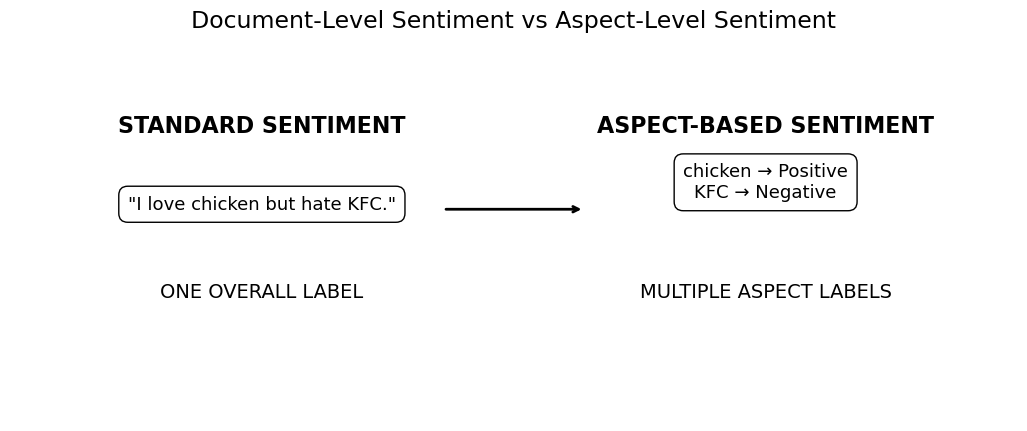

In [24]:
# CELL 30 — Visual comparison: document-level vs aspect-level

fig, ax = plt.subplots(figsize=(13, 5))
ax.axis("off")

ax.text(0.25, 0.75, "STANDARD SENTIMENT",
        ha="center", fontsize=16, fontweight="bold")

ax.text(
    0.25, 0.55,
    '"I love chicken but hate KFC."',
    ha="center", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black")
)

ax.text(0.25, 0.32, "ONE OVERALL LABEL",
        ha="center", fontsize=14)

ax.text(0.75, 0.75, "ASPECT-BASED SENTIMENT",
        ha="center", fontsize=16, fontweight="bold")

ax.text(
    0.75, 0.58,
    "chicken → Positive\nKFC → Negative",
    ha="center", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black")
)

ax.text(0.75, 0.32, "MULTIPLE ASPECT LABELS",
        ha="center", fontsize=14)

ax.annotate("", xy=(0.57, 0.55), xytext=(0.43, 0.55),
            arrowprops=dict(arrowstyle="->", lw=2))

plt.title("Document-Level Sentiment vs Aspect-Level Sentiment", fontsize=17)
plt.show()

## Part 3: Simple Automatic Aspect Extraction

So far, we manually supplied aspects.

For teaching purposes, spaCy can find **nouns and proper nouns** as candidate aspects.

Examples:

- food
- service
- battery
- camera
- restaurant

⚠️ This is a simple educational heuristic, not a production-quality aspect extractor.

In [25]:

# CELL 32 — Verify the spaCy English model

print("spaCy pipeline:", nlp.pipe_names)
print("✅ spaCy English model is ready.")


spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']
✅ spaCy English model is ready.


In [26]:
# CELL 33 — Extract candidate aspects

sentence = (
    "The camera is excellent, the battery is terrible, "
    "and the phone design is beautiful."
)

doc = nlp(sentence)

possible_aspects = []

for token in doc:
    if token.pos_ in ["NOUN", "PROPN"]:
        if token.text.lower() not in [
            aspect.lower() for aspect in possible_aspects
        ]:
            possible_aspects.append(token.text)

print("Sentence:")
print(sentence)

print("\nCandidate aspects:")
print(possible_aspects)

Sentence:
The camera is excellent, the battery is terrible, and the phone design is beautiful.

Candidate aspects:
['camera', 'battery', 'phone', 'design']


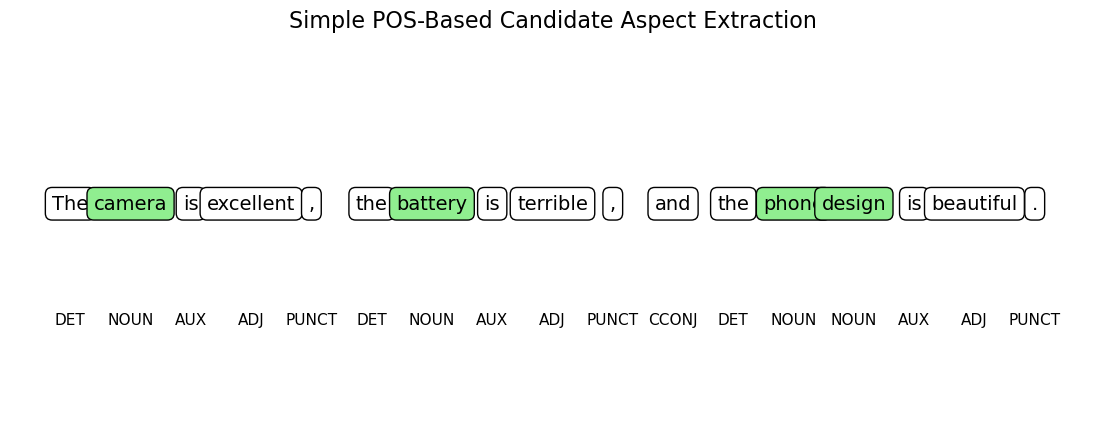

🟩 Green boxes = noun/proper-noun candidates


In [27]:
# CELL 34 — Visualize aspect extraction

doc = nlp(sentence)

words = [token.text for token in doc]
pos_tags = [token.pos_ for token in doc]

fig, ax = plt.subplots(figsize=(14, 5))
ax.axis("off")

for i, (word, pos) in enumerate(zip(words, pos_tags)):
    is_candidate = pos in ["NOUN", "PROPN"]

    ax.text(
        i, 0.55, word,
        ha="center", fontsize=14,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white" if not is_candidate else "lightgreen",
            edgecolor="black"
        )
    )

    ax.text(i, 0.25, pos, ha="center", fontsize=11)

ax.set_xlim(-1, len(words))
ax.set_ylim(0, 1)
ax.set_title("Simple POS-Based Candidate Aspect Extraction", fontsize=16)
plt.show()

print("🟩 Green boxes = noun/proper-noun candidates")

In [28]:

# CELL 35 — Automatic ABSA

def automatic_absa(sentence):
    """
    Educational automatic ABSA:
    1. Extract noun/proper-noun candidates with spaCy.
    2. Send each candidate as text_pair to the ABSA classifier.

    This is a classroom prototype, not a production-grade aspect extractor.
    """
    doc = nlp(sentence)

    aspects = []
    seen = set()

    for token in doc:
        if token.pos_ in ["NOUN", "PROPN"]:
            key = token.text.lower()
            if key not in seen:
                aspects.append(token.text)
                seen.add(key)

    results = []

    for aspect in aspects:
        prediction = absa_pipeline(
            sentence,
            text_pair=aspect
        )[0]

        results.append({
            "Aspect": aspect,
            "Sentiment": prediction["label"],
            "Confidence": prediction["score"]
        })

    return pd.DataFrame(
        results,
        columns=["Aspect", "Sentiment", "Confidence"]
    )

auto_result = automatic_absa(sentence)

if not auto_result.empty:
    auto_result["Confidence %"] = (
        auto_result["Confidence"] * 100
    ).round(2)
    display(auto_result[["Aspect", "Sentiment", "Confidence %"]])
else:
    print("No noun/proper-noun aspect candidates were found.")


,Aspect,Sentiment,Confidence %
0,camera,Positive,99.71
1,battery,Negative,99.16
2,phone,Positive,96.82
3,design,Positive,99.53


In [29]:
# CELL 36 — Realistic mixed product review

product_review = (
    "The laptop has an excellent display and a fast processor, "
    "but the battery life is disappointing and the keyboard feels cheap."
)

print("Review:")
print(product_review)

product_result = automatic_absa(product_review)

if len(product_result) > 0:
    product_result["Confidence %"] = (
        product_result["Confidence"] * 100
    ).round(2)

display(product_result[["Aspect", "Sentiment", "Confidence %"]])

Review:
The laptop has an excellent display and a fast processor, but the battery life is disappointing and the keyboard feels cheap.


,Aspect,Sentiment,Confidence %
0,laptop,Neutral,80.11
1,display,Positive,99.70
2,processor,Positive,99.62
3,battery,Negative,99.56
4,life,Negative,99.65
5,keyboard,Negative,99.60


In [30]:
# CELL 37 — Manual aspects can be more precise

manual_aspects = [
    "display",
    "processor",
    "battery life",
    "keyboard"
]

manual_result = analyze_aspects(
    product_review,
    manual_aspects
)

manual_result["Confidence %"] = (
    manual_result["Confidence"] * 100
).round(2)

display(manual_result[["Aspect", "Sentiment", "Confidence %"]])

,Aspect,Sentiment,Confidence %
0,display,Positive,99.70
1,processor,Positive,99.62
2,battery life,Negative,99.61
3,keyboard,Negative,99.60


## Complete ABSA pipeline

A practical ABSA system can be understood as:

**Review**
↓
**Aspect Extraction**
↓
**Aspect Identification**
↓
**Aspect Sentiment Classification**
↓
**Structured Output / Dashboard**

Example:

```text
"The camera is excellent but the battery is terrible."

camera  → positive
battery → negative
```

The aspect-extraction and sentiment-classification steps can be separate components.

In [31]:
# CELL 39 — Final ABSA dashboard

final_review = (
    "The food was delicious, the staff were friendly, "
    "but the service was slow and the prices were too high."
)

final_aspects = ["food", "staff", "service", "prices"]

final_result = analyze_aspects(
    final_review,
    final_aspects
)

final_result["Confidence %"] = (
    final_result["Confidence"] * 100
).round(2)

print("📝 FINAL REVIEW")
print(final_review)

display(final_result[["Aspect", "Sentiment", "Confidence %"]])

📝 FINAL REVIEW
The food was delicious, the staff were friendly, but the service was slow and the prices were too high.


,Aspect,Sentiment,Confidence %
0,food,Positive,99.69
1,staff,Positive,99.42
2,service,Negative,99.51
3,prices,Negative,99.51


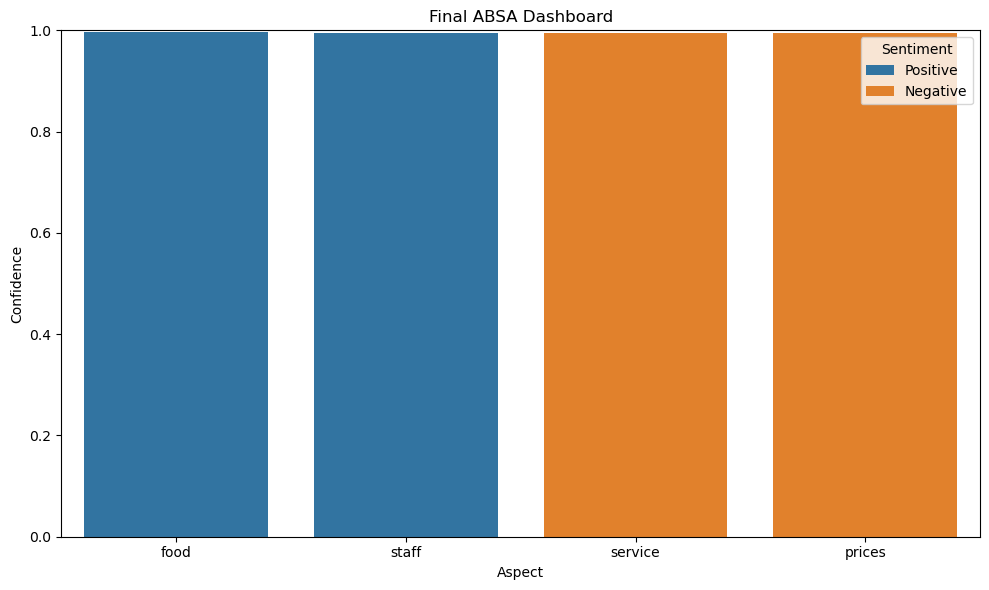

In [32]:

# CELL 40 — Final dashboard visualization

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_result,
    x="Aspect",
    y="Confidence",
    hue="Sentiment",
    dodge=False
)

plt.ylim(0, 1)
plt.xlabel("Aspect")
plt.ylabel("Confidence")
plt.title("Final ABSA Dashboard")
plt.tight_layout()
plt.show()


C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Jitesh\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}

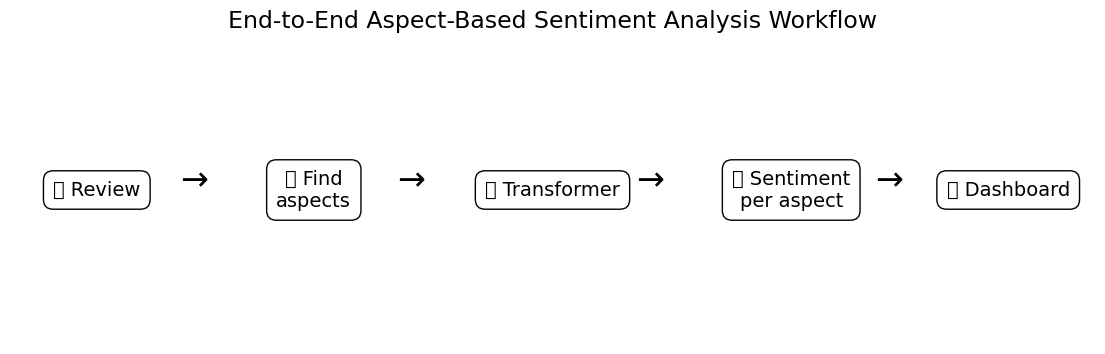

In [33]:
# CELL 41 — End-to-end workflow drawing

fig, ax = plt.subplots(figsize=(14, 4))
ax.axis("off")

steps = [
    ("📝 Review", 0.08),
    ("🔍 Find\naspects", 0.28),
    ("🧠 Transformer", 0.50),
    ("🎯 Sentiment\nper aspect", 0.72),
    ("📊 Dashboard", 0.92)
]

for label, x in steps:
    ax.text(
        x, 0.5, label,
        ha="center", va="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black")
    )

for x in [0.18, 0.38, 0.60, 0.82]:
    ax.annotate("→", xy=(x + 0.035, 0.5), xytext=(x - 0.01, 0.5),
                fontsize=24, ha="center")

plt.title("End-to-End Aspect-Based Sentiment Analysis Workflow", fontsize=17)
plt.show()

## Part 4: Classroom Assessment & Challenge Solutions

### Conceptual Questions & Answers

**1. What is sentiment analysis?**  
Sentiment analysis (opinion mining) is the NLP task of computationally determining the emotional tone, subjective attitude, or polarity (positive, negative, neutral) expressed in written text.

**2. What is BERT?**  
BERT (Bidirectional Encoder Representations from Transformers) is a transformer encoder model introduced by Devlin et al. (2018). It is pretrained on unlabeled text using Masked Language Modeling (MLM) and Next Sentence Prediction (NSP), allowing it to capture rich bidirectional context for downstream classification tasks.

**3. What does a tokenizer do?**  
A tokenizer converts raw natural language strings into numerical token IDs that neural networks can process. BERT uses WordPiece tokenization, which segments common words into full tokens and rare words into sub-word units, adding special markers like `[CLS]` (classification token) and `[SEP]` (sentence separator).

**4. What is a pretrained model?**  
A pretrained model is a neural network that has already learned general language representations by training on massive corpora (e.g. Wikipedia, BookCorpus). It can be directly used for zero-shot inference or fine-tuned on specific domain tasks with minimal additional data.

**5. What is confidence?**  
Confidence is the model's calibrated probability (typically the softmax score between 0.0 and 1.0) assigned to the predicted label. High confidence indicates strong model certainty, while scores near 0.5 denote high ambiguity.

**6. Why can a mixed review be difficult for binary sentiment classification?**  
Binary sentiment classification assigns a single global label to an entire document. When a review contains contrasting polarities (e.g., praise for the food but complaint about the price), a document-level classifier is forced to compress opposing sentiments into one label, often misclassifying one aspect or producing an unconfident middle score.

**7. What is ABSA?**  
Aspect-Based Sentiment Analysis (ABSA) is a fine-grained NLP task that breaks down text into specific attributes/aspects and determines the distinct sentiment directed toward each individual aspect.

**8. Why do we provide an aspect to an ABSA model?**  
Providing the aspect as a `text_pair` (or conditioning query) allows cross-attention mechanisms in the transformer to focus specifically on the relationship between that target entity and its governing adjectives/verbs in the sentence.

**9. What is the difference between document-level and aspect-level sentiment?**  
Document-level sentiment outputs a single coarse classification for the whole text (e.g., *"The overall movie was positive"*). Aspect-level sentiment provides a multi-dimensional breakdown for every component (e.g., *acting: positive, pacing: negative, music: positive*).

**10. Why is simple noun extraction not a complete aspect-extraction solution?**  
Simple POS tagging for nouns extracts every noun (including background or non-evaluative words like *"yesterday"*, *"table"*, *"friend"*), while missing multi-word noun phrases (*"battery life"*, *"customer service"*) and implicit aspects (*"it took forever"* implies *wait time* without mentioning a noun).


Sentence: The camera takes amazing photos, but the battery drains quickly and the screen is too dim.
Target Aspects: ['camera', 'photos', 'battery', 'screen']



,Aspect,Sentiment,Confidence %
0,camera,Positive,95.79
1,photos,Positive,99.62
2,battery,Negative,99.56
3,screen,Negative,99.58


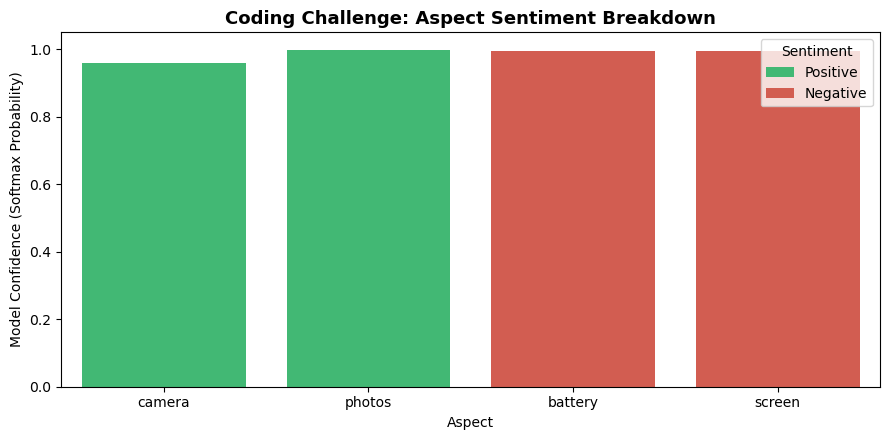

In [34]:
# Coding Challenge Solution
# Analyze: 'The camera takes amazing photos, but the battery drains quickly and the screen is too dim.'

challenge_sentence = (
    "The camera takes amazing photos, but the battery drains quickly "
    "and the screen is too dim."
)
challenge_aspects = ["camera", "photos", "battery", "screen"]

print("Sentence:", challenge_sentence)
print("Target Aspects:", challenge_aspects)
print()

challenge_result = analyze_aspects(challenge_sentence, challenge_aspects)
challenge_result["Confidence %"] = (challenge_result["Confidence"] * 100).round(2)

display(challenge_result[["Aspect", "Sentiment", "Confidence %"]])

# Visualize challenge results
plt.figure(figsize=(9, 4.5))
palette = {"Positive": "#2ecc71", "Negative": "#e74c3c", "Neutral": "#95a5a6"}
sns.barplot(
    data=challenge_result,
    x="Aspect",
    y="Confidence",
    hue="Sentiment",
    palette=palette,
    dodge=False
)
plt.ylim(0, 1.05)
plt.title("Coding Challenge: Aspect Sentiment Breakdown", fontsize=13, fontweight='bold')
plt.ylabel("Model Confidence (Softmax Probability)")
plt.tight_layout()
plt.show()


## Part 5: Final Summary

### Standard BERT sentiment analysis

**Text → Tokenizer → BERT → Classification → Overall sentiment**

### Mixed reviews

One review may contain several opinions.

Example:

> "I love chicken but hate KFC."

### ABSA

**Sentence + Aspect → Aspect Sentiment**

```text
chicken → positive
KFC     → negative
```

### Big takeaway

**Ordinary sentiment analysis asks:**

> What is the overall sentiment?

**ABSA asks:**

> What is the sentiment toward each aspect?

This distinction is a useful foundation for practical NLP applications.

## Technical References & Model Specifications

### Models Used
1. **Document-Level Sentiment Analysis**: [`textattack/bert-base-uncased-SST-2`](https://huggingface.co/textattack/bert-base-uncased-SST-2)  
   - Base BERT architecture fine-tuned on the Stanford Sentiment Treebank (SST-2).
2. **Aspect-Based Sentiment Analysis**: [`yangheng/deberta-v3-base-absa-v1.1`](https://huggingface.co/yangheng/deberta-v3-base-absa-v1.1)  
   - DeBERTa-v3 architecture trained specifically for Aspect-Based Sentiment Analysis with `text_pair=aspect` conditioning.
3. **Linguistic Processing**: `spacy` (`en_core_web_sm`)  
   - Part-of-Speech (POS) tagging and noun phrase chunking.

### Environment Stability
- NLP-only pipeline avoiding unnecessary computer vision libraries to prevent runtime ABI conflicts.
